# Customer Churn Prediction Using Logistic Regression

## Business Scenario

A telecom company is facing a serious issue with customer churn. Every time a customer leaves the company, the company loses revenue and must spend additional money to acquire a new customer.

Management wants to identify customers who are likely to leave so that proactive retention offers can be provided.

As a Data Analyst, the objective is to analyze customer data and build a machine learning model that can predict whether a customer is likely to churn.

## Objective

Build a Logistic Regression model that estimates the probability of customer churn and classifies customers as either likely to churn or likely to stay.

## Tasks

1. Load the Telco Customer Churn dataset and understand the available customer attributes.
2. Identify relevant input features that may influence customer churn.
3. Build a model that estimates the probability of a customer leaving the company.
4. Classify customers into:
   - Likely to churn
   - Likely to stay
5. Predict the churn outcome for unseen customer records.
6. Evaluate the performance of the model using appropriate metrics.
7. Analyze how many churn customers were correctly identified.
8. Analyze how many non-churn customers were misclassified.
9. Interpret the results from a business perspective.
10. Determine whether it is more costly to wrongly flag a loyal customer or miss a customer who is actually going to leave.
11. Suggest one improvement to make the prediction more reliable.

## Machine Learning Approach

- **Type:** Supervised Learning
- **Problem:** Binary Classification
- **Algorithm:** Logistic Regression
- **Input Features (X):** Relevant customer attributes
- **Target Variable (y):** Churn

In [2]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("Telco-Customer-Churn.csv")

# Display the first 5 rows
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Understanding the Customer Dataset

Before building the classification model, we need to understand the customer attributes available in the dataset.

We will examine:

- The number of customers and attributes.
- The names of all columns.
- The data types of the columns.
- The number of missing values.
- The distribution of the target variable, Churn.

This analysis helps us identify which customer attributes can be used as input features for predicting customer churn.

In [3]:

print("Shape of the dataset:", df.shape)


print("\nColumn names:")
print(df.columns.tolist())


print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Shape of the dataset: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 n

## 4. Data Cleaning

Before building the machine learning model, the dataset needs to be checked and cleaned.

The `TotalCharges` column represents the total amount charged to a customer. However, some records may contain blank values, causing this column to be treated as a text column instead of a numerical column.

We will:

- Convert `TotalCharges` into a numeric data type.
- Convert invalid or blank values into missing values.
- Check the number of missing values.
- Remove records with missing `TotalCharges` values.

This ensures that the numerical data is in a suitable format for Logistic Regression.

In [4]:

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')


print("Missing values in TotalCharges:", df['TotalCharges'].isnull().sum())

Missing values in TotalCharges: 11


In [5]:

df = df.dropna(subset=['TotalCharges'])

print("Shape after cleaning:", df.shape)

Shape after cleaning: (7032, 21)


In [6]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [7]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [8]:
df = df.dropna(subset=['TotalCharges'])

In [9]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## 5. Identifying Relevant Input Features

The target variable for this project is `Churn`, which indicates whether a customer has left the telecom company.

We need to select customer attributes that may influence churn as input features.

Potentially useful features include:

- `gender`
- `SeniorCitizen`
- `Partner`
- `Dependents`
- `tenure`
- `PhoneService`
- `MultipleLines`
- `InternetService`
- `OnlineSecurity`
- `OnlineBackup`
- `DeviceProtection`
- `TechSupport`
- `StreamingTV`
- `StreamingMovies`
- `Contract`
- `PaperlessBilling`
- `PaymentMethod`
- `MonthlyCharges`
- `TotalCharges`

The `customerID` column will not be used because it is only an identifier and does not provide meaningful information about customer churn.

The target variable is `Churn`.

In [10]:
df = df.drop('customerID', axis=1)


X = df.drop('Churn', axis=1)
y = df['Churn']

print("Input features:")
print(X.columns.tolist())

print("\nTarget variable:")
print(y.name)

Input features:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']

Target variable:
Churn


In [11]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFirst 5 rows of X:")
display(X.head())

print("\nFirst 5 values of y:")
display(y.head())

X shape: (7032, 19)
y shape: (7032,)

First 5 rows of X:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65



First 5 values of y:


0     No
1     No
2    Yes
3     No
4    Yes
Name: Churn, dtype: object

## 6. Encoding Categorical Features

The Telco Customer Churn dataset contains both numerical and categorical features.

Logistic Regression requires numerical input, so categorical variables must be converted into numerical form.

We will use One-Hot Encoding to convert categorical features into binary numerical columns.

For example, a categorical feature such as Contract can be represented using separate binary columns for its different categories.

The `drop_first=True` option is used to remove one category from each categorical feature and avoid redundant information.

The target variable `Churn` will also be converted into numerical values:

- No = 0
- Yes = 1

In [12]:
# Convert categorical input features into numerical features
X_encoded = pd.get_dummies(X, drop_first=True, dtype=int)

# Display the first 5 rows
X_encoded.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0


In [14]:
y_encoded = y.map({'No': 0, 'Yes': 1})


y_encoded.head()

0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64

In [15]:
print("Encoded X shape:", X_encoded.shape)
print("\nEncoded X columns:")
print(X_encoded.columns.tolist())

print("\nEncoded target values:")
print(y_encoded.value_counts())

Encoded X shape: (7032, 30)

Encoded X columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']

Encoded target values:
Churn
0    5163
1    1869
Name: count, dtype: int64


## Splitting the Dataset into Training and Testing Data

The encoded dataset is divided into training and testing sets so that the Logistic Regression model can be trained on one portion of the data and evaluated on unseen data.

- **Training data (80%)** is used to learn the relationship between customer attributes and churn.
- **Testing data (20%)** is used to evaluate how well the trained model predicts churn for unseen customers.

The `random_state` ensures that the same split is obtained each time the code is executed.

The `stratify` parameter is used with the Churn target so that the proportion of churn and non-churn customers remains approximately the same in both training and testing datasets.

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (5625, 30)
Testing features: (1407, 30)
Training target: (5625,)
Testing target: (1407,)


## 8. Building and Training the Logistic Regression Model

Logistic Regression is used because the target variable has two possible outcomes:

- 0 → Customer is likely to stay
- 1 → Customer is likely to churn

The model learns the relationship between customer attributes and the probability of churn.

After training, the model can:
- Estimate the probability of churn.
- Classify customers as likely to churn or likely to stay.
- Predict churn for unseen customer records.

In [18]:
from sklearn.linear_model import LogisticRegression


model = LogisticRegression(max_iter=1000)


model.fit(X_train, y_train)

c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

## 9. Predicting Churn for Unseen Customers

The trained Logistic Regression model is used to predict churn for the testing dataset.

The testing data was not used during training, so it represents unseen customer records.

The model will classify each customer as:

- 0 → Likely to Stay
- 1 → Likely to Churn

In [19]:
# Predict churn class for unseen customers
y_pred = model.predict(X_test)


print("Predicted Churn:")
print(y_pred[:20])

Predicted Churn:
[0 1 0 0 0 0 0 0 1 0 1 0 1 0 0 1 1 1 0 0]


## 10. Estimating Churn Probability

Logistic Regression can provide the probability that each customer belongs to the churn class.

The `predict_proba()` function returns two probabilities:

- Probability of staying (class 0)
- Probability of churning (class 1)

The probability of churn is taken from the second column.

In [20]:
y_probability = model.predict_proba(X_test)[:, 1]

# Display the first 10 churn probabilities
print("Churn Probabilities:")
print(y_probability[:10])

Churn Probabilities:
[0.01803384 0.58326644 0.00457417 0.20396093 0.10528705 0.47917863
 0.02524995 0.16636368 0.66764473 0.01544408]


## 11. Confusion Matrix

A confusion matrix is used to evaluate the classification performance of the Logistic Regression model.

It compares the actual customer churn status with the predicted churn status.

The confusion matrix contains four outcomes:

- **True Negative (TN):** Customer actually stayed and the model correctly predicted stay.
- **True Positive (TP):** Customer actually churned and the model correctly predicted churn.
- **False Positive (FP):** Customer actually stayed but the model incorrectly predicted churn.
- **False Negative (FN):** Customer actually churned but the model incorrectly predicted stay.

The confusion matrix helps us understand not only the overall accuracy of the model but also the specific types of mistakes it makes.

In [21]:
from sklearn.metrics import confusion_matrix

# Create the confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[915 118]
 [159 215]]


## 12. Interpreting the Confusion Matrix

The confusion matrix is displayed with:

- Rows representing the actual churn status.
- Columns representing the predicted churn status.

The four values are interpreted as:

**True Negative (TN):** Correctly identified customers who stayed.

**False Positive (FP):** Customers who stayed but were incorrectly flagged as likely to churn.

**False Negative (FN):** Customers who churned but were incorrectly predicted to stay.

**True Positive (TP):** Correctly identified customers who churned.

In [22]:
tn, fp, fn, tp = cm.ravel()

print("True Negative (TN):", tn)
print("False Positive (FP):", fp)
print("False Negative (FN):", fn)
print("True Positive (TP):", tp)

True Negative (TN): 915
False Positive (FP): 118
False Negative (FN): 159
True Positive (TP): 215


## 13. Evaluating Classification Performance

The Logistic Regression model is evaluated using Accuracy, Precision, Recall, and F1-score.

- **Accuracy:** Percentage of all customers that were classified correctly.
- **Precision:** Of the customers predicted as churn, how many actually churned.
- **Recall:** Of the customers who actually churned, how many were correctly identified.
- **F1-score:** A combined measure of Precision and Recall.

For customer churn prediction, Recall is particularly important because it measures how effectively the model identifies customers who are actually going to churn.

In [23]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate classification metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

Accuracy: 0.8031272210376688
Precision: 0.6456456456456456
Recall: 0.5748663101604278
F1-score: 0.6082036775106082


## 14. Business Interpretation

In a telecom company, both False Positives and False Negatives have business costs.

A **False Positive** occurs when a loyal customer is incorrectly predicted to churn. The company may unnecessarily provide a retention offer, resulting in additional promotional costs.

A **False Negative** occurs when a customer who is actually going to churn is predicted to stay. This can be more costly because the company misses the opportunity to intervene and potentially retain the customer.

Therefore, in many customer retention scenarios, reducing False Negatives is especially important. A model with good Recall can help identify more customers who are genuinely at risk of leaving.

However, the ideal balance depends on the actual cost of retention offers compared with the revenue lost when a customer churns.

## 15. Visualizing the Confusion Matrix

The confusion matrix is visualized as a heatmap to clearly show the number of customers correctly and incorrectly classified as churn or non-churn.

This visualization helps identify True Positives, True Negatives, False Positives, and False Negatives.

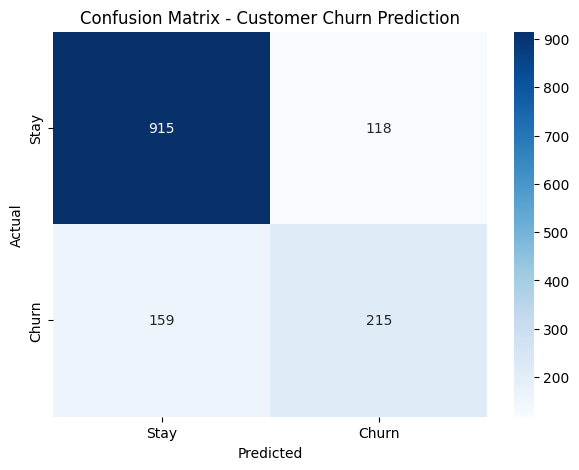

In [24]:
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Stay', 'Churn'],
    yticklabels=['Stay', 'Churn']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Customer Churn Prediction")

plt.show()

## 16. Classification Report

The classification report provides Precision, Recall, F1-score, and Support for both classes.

Class 0 represents customers who stayed, while Class 1 represents customers who churned.

In [25]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=['Stay', 'Churn']
))

              precision    recall  f1-score   support

        Stay       0.85      0.89      0.87      1033
       Churn       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



## 17. Predicting an Unseen Customer

A customer from the testing dataset is used as an unseen customer record.

The trained model predicts both the churn probability and the final churn classification.

The testing record was not used during model training.

In [26]:
y_pred = model.predict(X_test)

In [27]:

customer = X_test.iloc[[0]]


churn_probability = model.predict_proba(customer)[0][1]

churn_prediction = model.predict(customer)[0]

print("Churn Probability:", churn_probability)

if churn_prediction == 1:
    print("Prediction: Likely to Churn")
else:
    print("Prediction: Likely to Stay")

Churn Probability: 0.018033841368923335
Prediction: Likely to Stay


## 18. Technical Improvement

One way to make the churn prediction more reliable is to use K-Fold Cross-Validation.

Instead of evaluating the model using only one train-test split, K-Fold Cross-Validation divides the training data into multiple folds and trains and evaluates the model several times.

This provides a more reliable estimate of model performance and helps determine whether the model generalizes well to unseen customers.

Another possible improvement would be to compare Logistic Regression with other classification algorithms and tune the classification threshold based on the business cost of False Positives and False Negatives.

## 19. Conclusion

A Logistic Regression model was developed to predict customer churn for a telecom company.

The Telco Customer Churn dataset was cleaned by converting the `TotalCharges` column into a numerical format and handling missing values. The `customerID` column was removed because it is only an identifier and does not provide useful predictive information.

Categorical customer attributes were converted into numerical features using One-Hot Encoding. The dataset was then divided into 80% training data and 20% testing data.

The Logistic Regression model was trained using the customer attributes and used to predict both the probability and classification of customer churn.

The model was evaluated using Accuracy, Precision, Recall, F1-score, and a Confusion Matrix. The confusion matrix helped identify True Positives, True Negatives, False Positives, and False Negatives.

For the telecom business, correctly identifying customers who are actually going to churn is particularly important because these customers can be targeted with proactive retention offers. False Negatives can result in missed retention opportunities, while False Positives can lead to unnecessary retention costs.

A recommended technical improvement is to use K-Fold Cross-Validation and tune the classification threshold according to the business cost of False Positives and False Negatives.